# Clase 3 : Modelos Lineales Regularizados

En esta sesión, aprenderemos como, haciendo uso de sklearn, estimar modelos de regresión lineal regulariazados (e.g Lasso, Ridge, ElasticNet). Adicional a esto, declararemos una serie de funciones que serán de utilidad en la generación de rezagos en la data (**crealags**), para generar listas ordenadas con todos los modelos que queramos estimar (**creamodelos**),  y finalmente otra que será útil para la presentación de las métricas de desempeño de dichos modelos en cada una de las muestras (**metricas**).

Primero cargaremos la base de datoa a utilizar.

In [3]:
# Instalar dependencias (ejecutar una vez si da error)
%pip install openpyxl statsmodels -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import subprocess
import sys

# Instalar openpyxl si no está instalado (necesario para .xlsx)
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'openpyxl', '-q'])

excel_file = 'data_usd-clp.xlsx'
data = pd.read_excel(excel_file, engine='openpyxl')

## Descripción de la base de datos

La base **data_usd-clp.xlsx** contiene series temporales de variables financieras y macroeconómicas relacionadas con el tipo de cambio USD/CLP (peso chileno).

| Variable | Descripción |
|----------|-------------|
| **USDCLP Curncy** | Tipo de cambio USD/CLP spot (variable objetivo) |
| **USSW1 Curncy** | Tasa swap USD 1 año |
| **USSW10 Curncy** | Tasa swap USD 10 años |
| **CHSWP1 ICCH Curncy** | Swap Chile 1 año |
| **CHSWP10 Curncy** | Swap Chile 10 años |
| **CCHIL1U5 CBIN Curncy** | Credit default swap Chile 5 años |
| **HGA Comdty** | Oro (commodity) |
| **CL1 Comdty** | Petróleo WTI |
| **VIX Index** | Índice de volatilidad implícita |

In [5]:
# Dimensiones y estructura
print("Dimensiones:", data.shape)
print("\nInformación de columnas:")
data.info()
print("\n" + "="*60)
print("Primeras filas:")
data.head(10)

Dimensiones: (1251, 11)

Información de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 1251 entries, 0 to 1250
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Unnamed: 0            1251 non-null   datetime64[us]
 1   USDCLP Curncy         1251 non-null   float64       
 2   USSW1 Curncy          1251 non-null   float64       
 3   USSW10 Curncy         1251 non-null   float64       
 4   CHSWP1 ICCH Curncy    1251 non-null   float64       
 5   CHSWP10 Curncy        1251 non-null   float64       
 6   CCHIL1U5 CBIN Curncy  1251 non-null   float64       
 7   HGA Comdty            1251 non-null   float64       
 8   CL1 Comdty            1251 non-null   float64       
 9   VIX Index             1251 non-null   float64       
 10  JPY Curncy            1251 non-null   float64       
dtypes: datetime64[us](1), float64(10)
memory usage: 107.6 KB

Primeras filas:


,Unnamed: 0,USDCLP Curncy,USSW1 Curncy,USSW10 Curncy,CHSWP1 ICCH Curncy,CHSWP10 Curncy,CCHIL1U5 CBIN Curncy,HGA Comdty,CL1 Comdty,VIX Index,JPY Curncy
0,2012-12-28,479.470,0.3340,1.7630,5.23,5.47000,72.603,344.35,90.80,22.72,85.96
1,2012-12-31,476.404,0.3240,1.8395,5.26,5.47000,72.479,350.65,91.82,18.02,86.75
2,2013-01-01,475.382,0.3210,1.8395,5.27,5.47000,72.136,354.90,92.47,16.35,86.70
3,2013-01-02,474.360,0.3205,1.8781,5.28,5.50000,70.128,359.15,93.12,14.68,87.34
4,2013-01-03,472.420,0.3215,1.9455,5.28,5.53000,67.005,357.35,92.92,14.56,87.24
5,2013-01-04,473.120,0.3300,1.9360,5.27,5.55000,66.833,355.30,93.09,13.83,88.15
6,2013-01-07,471.340,0.3280,1.9270,5.28,5.58000,68.502,354.05,93.19,13.79,87.79
7,2013-01-08,472.250,0.3230,1.8910,5.27,5.55499,69.658,353.75,93.15,13.62,87.05
8,2013-01-09,470.950,0.3140,1.8875,5.25,5.54000,68.333,353.90,93.10,13.81,87.88
9,2013-01-10,470.780,0.3165,1.9242,5.26,5.55000,69.163,358.20,93.82,13.49,88.78


In [6]:
# Estadísticas descriptivas
print("Estadísticas descriptivas de las variables numéricas:")
data.describe().round(4)

Estadísticas descriptivas de las variables numéricas:


,Unnamed: 0,USDCLP Curncy,USSW1 Curncy,USSW10 Curncy,CHSWP1 ICCH Curncy,CHSWP10 Curncy,CCHIL1U5 CBIN Curncy,HGA Comdty,CL1 Comdty,VIX Index,JPY Curncy
count,1251,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000
mean,2015-05-22 19:11:04.748201,608.1012,0.6537,2.2515,3.5963,4.6958,86.4431,277.8099,67.3140,14.5910,108.8969
min,2012-12-28 00:00:00,467.2300,0.2530,1.2473,2.2800,3.8800,50.7480,198.5000,26.2100,9.1900,85.9600
25%,2014-03-11 12:00:00,551.7600,0.3235,2.0029,3.0500,4.2900,71.9675,241.1250,46.6750,12.4150,101.8900
50%,2015-05-22 00:00:00,625.7500,0.4900,2.2423,3.5500,4.6150,81.8880,276.5000,53.0100,13.7600,109.1800
75%,2016-08-02 12:00:00,667.2400,0.8880,2.5826,3.9000,5.0650,95.9480,314.3500,95.4400,15.7450,117.5200
max,2017-10-13 00:00:00,731.4000,1.6075,3.1847,5.2800,5.6150,150.9330,366.5000,110.5300,40.7400,125.6300
std,NaN,72.6656,0.3992,0.4220,0.7538,0.4674,19.9319,42.7162,25.3346,3.5744,8.9520


In [7]:
# Estadísticas descriptivas
print("Estadísticas descriptivas de las variables numéricas:")
data.describe().round(4)

Estadísticas descriptivas de las variables numéricas:


,Unnamed: 0,USDCLP Curncy,USSW1 Curncy,USSW10 Curncy,CHSWP1 ICCH Curncy,CHSWP10 Curncy,CCHIL1U5 CBIN Curncy,HGA Comdty,CL1 Comdty,VIX Index,JPY Curncy
count,1251,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000,1251.0000
mean,2015-05-22 19:11:04.748201,608.1012,0.6537,2.2515,3.5963,4.6958,86.4431,277.8099,67.3140,14.5910,108.8969
min,2012-12-28 00:00:00,467.2300,0.2530,1.2473,2.2800,3.8800,50.7480,198.5000,26.2100,9.1900,85.9600
25%,2014-03-11 12:00:00,551.7600,0.3235,2.0029,3.0500,4.2900,71.9675,241.1250,46.6750,12.4150,101.8900
50%,2015-05-22 00:00:00,625.7500,0.4900,2.2423,3.5500,4.6150,81.8880,276.5000,53.0100,13.7600,109.1800
75%,2016-08-02 12:00:00,667.2400,0.8880,2.5826,3.9000,5.0650,95.9480,314.3500,95.4400,15.7450,117.5200
max,2017-10-13 00:00:00,731.4000,1.6075,3.1847,5.2800,5.6150,150.9330,366.5000,110.5300,40.7400,125.6300
std,NaN,72.6656,0.3992,0.4220,0.7538,0.4674,19.9319,42.7162,25.3346,3.5744,8.9520


## Análisis Exploratorio: Gráficos y Descriptivas

Antes de la estimación de modelos, realizamos un análisis exploratorio visual de la distribución de las variables mediante histogramas, gráficos de densidad (KDE) y sus combinaciones.

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Seleccionar solo columnas numéricas
numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
print("Variables numéricas:", numeric_cols)

Variables numéricas: ['USDCLP Curncy', 'USSW1 Curncy', 'USSW10 Curncy', 'CHSWP1 ICCH Curncy', 'CHSWP10 Curncy', 'CCHIL1U5 CBIN Curncy', 'HGA Comdty', 'CL1 Comdty', 'VIX Index', 'JPY Curncy']


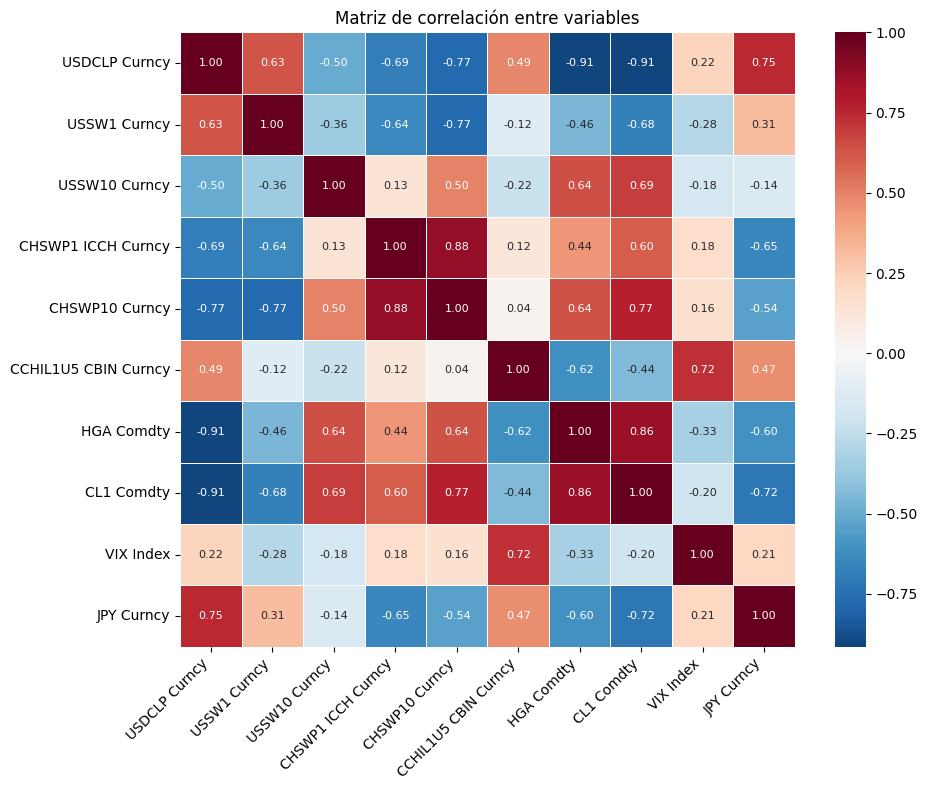

In [9]:
# Matriz de correlación (heatmap)
corr_matrix = data[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, 
            square=True, linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('Matriz de correlación entre variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

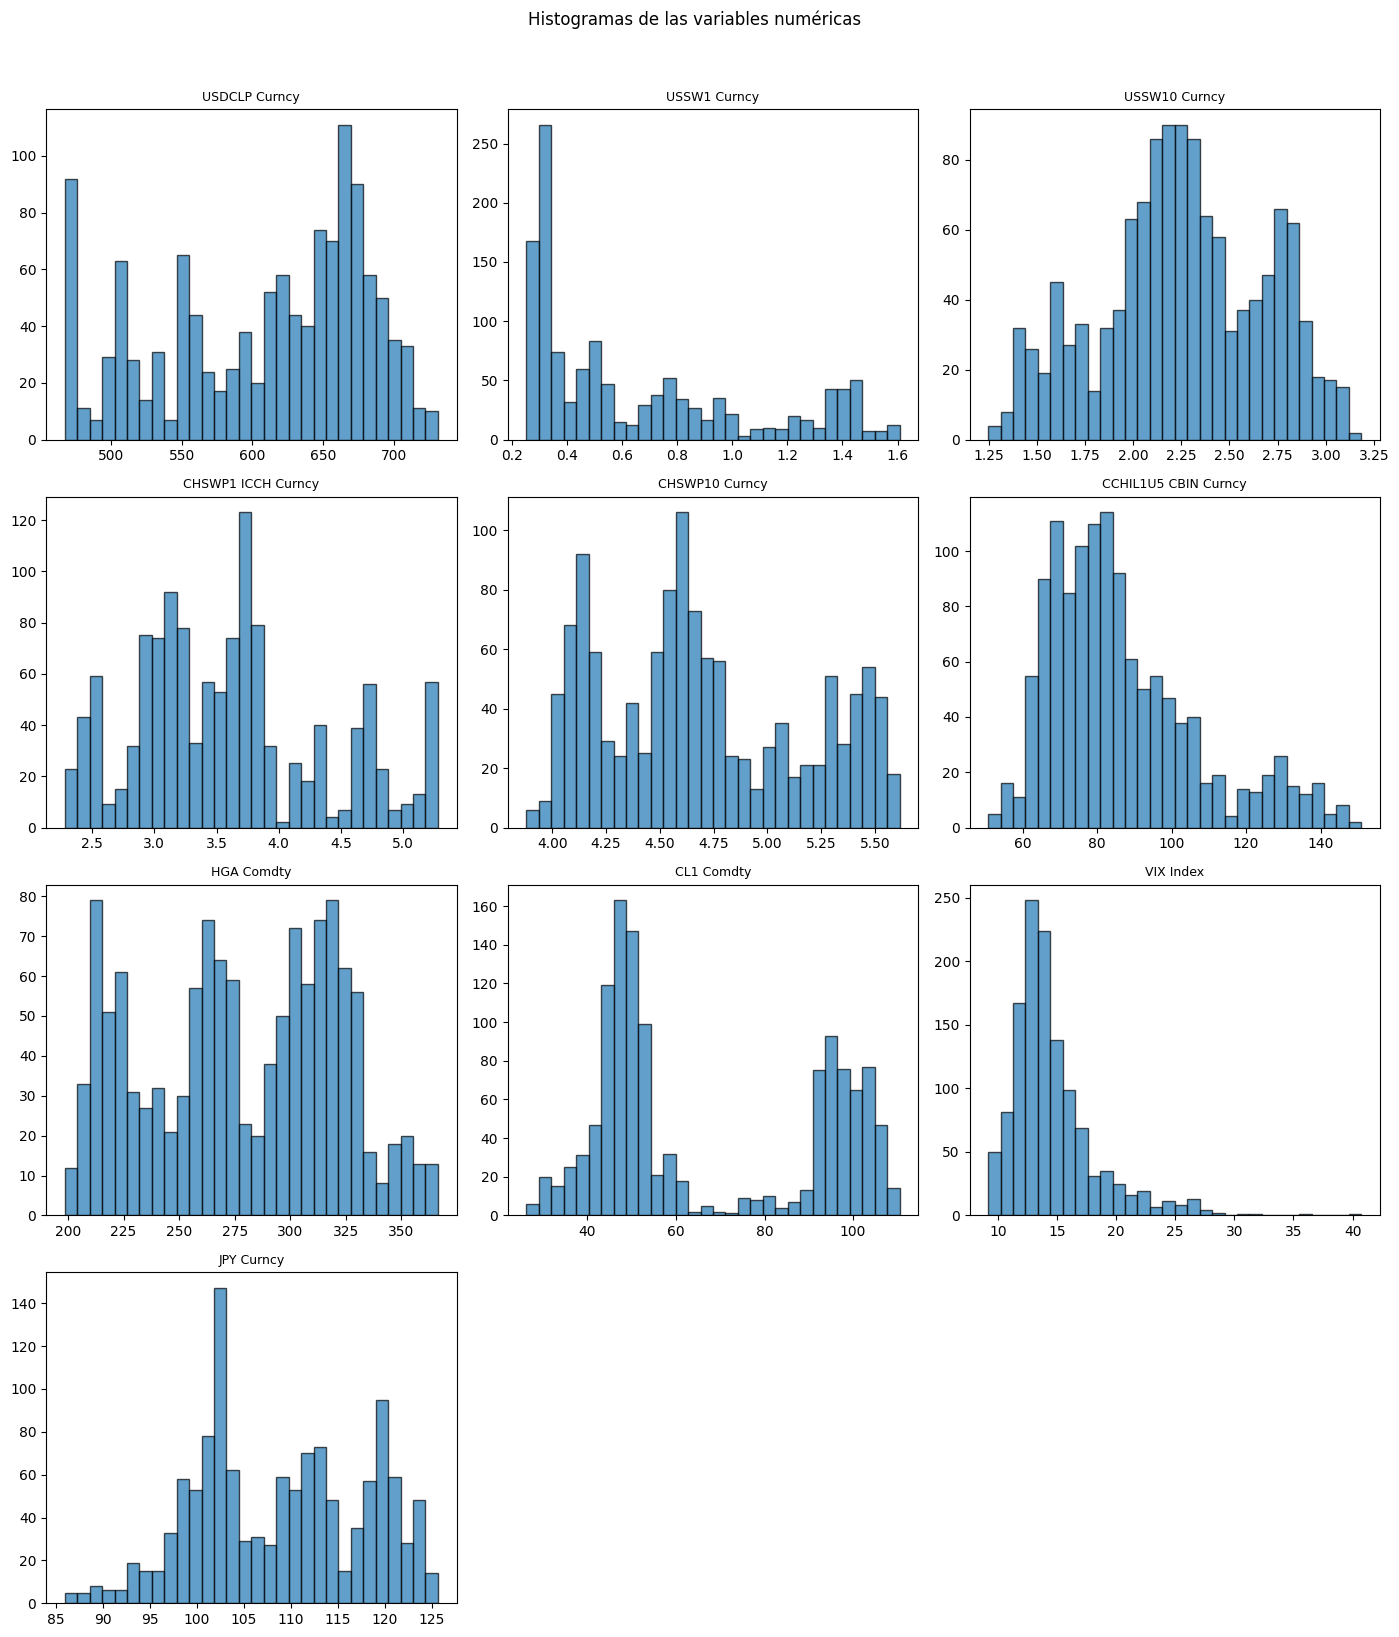

In [10]:
# 1. Histogramas individuales (una variable por subplot)
n_vars = len(numeric_cols)
n_cols_grid = 3
n_rows = (n_vars + n_cols_grid - 1) // n_cols_grid
fig, axes = plt.subplots(n_rows, n_cols_grid, figsize=(14, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()
for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col].dropna(), bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Histogramas de las variables numéricas', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

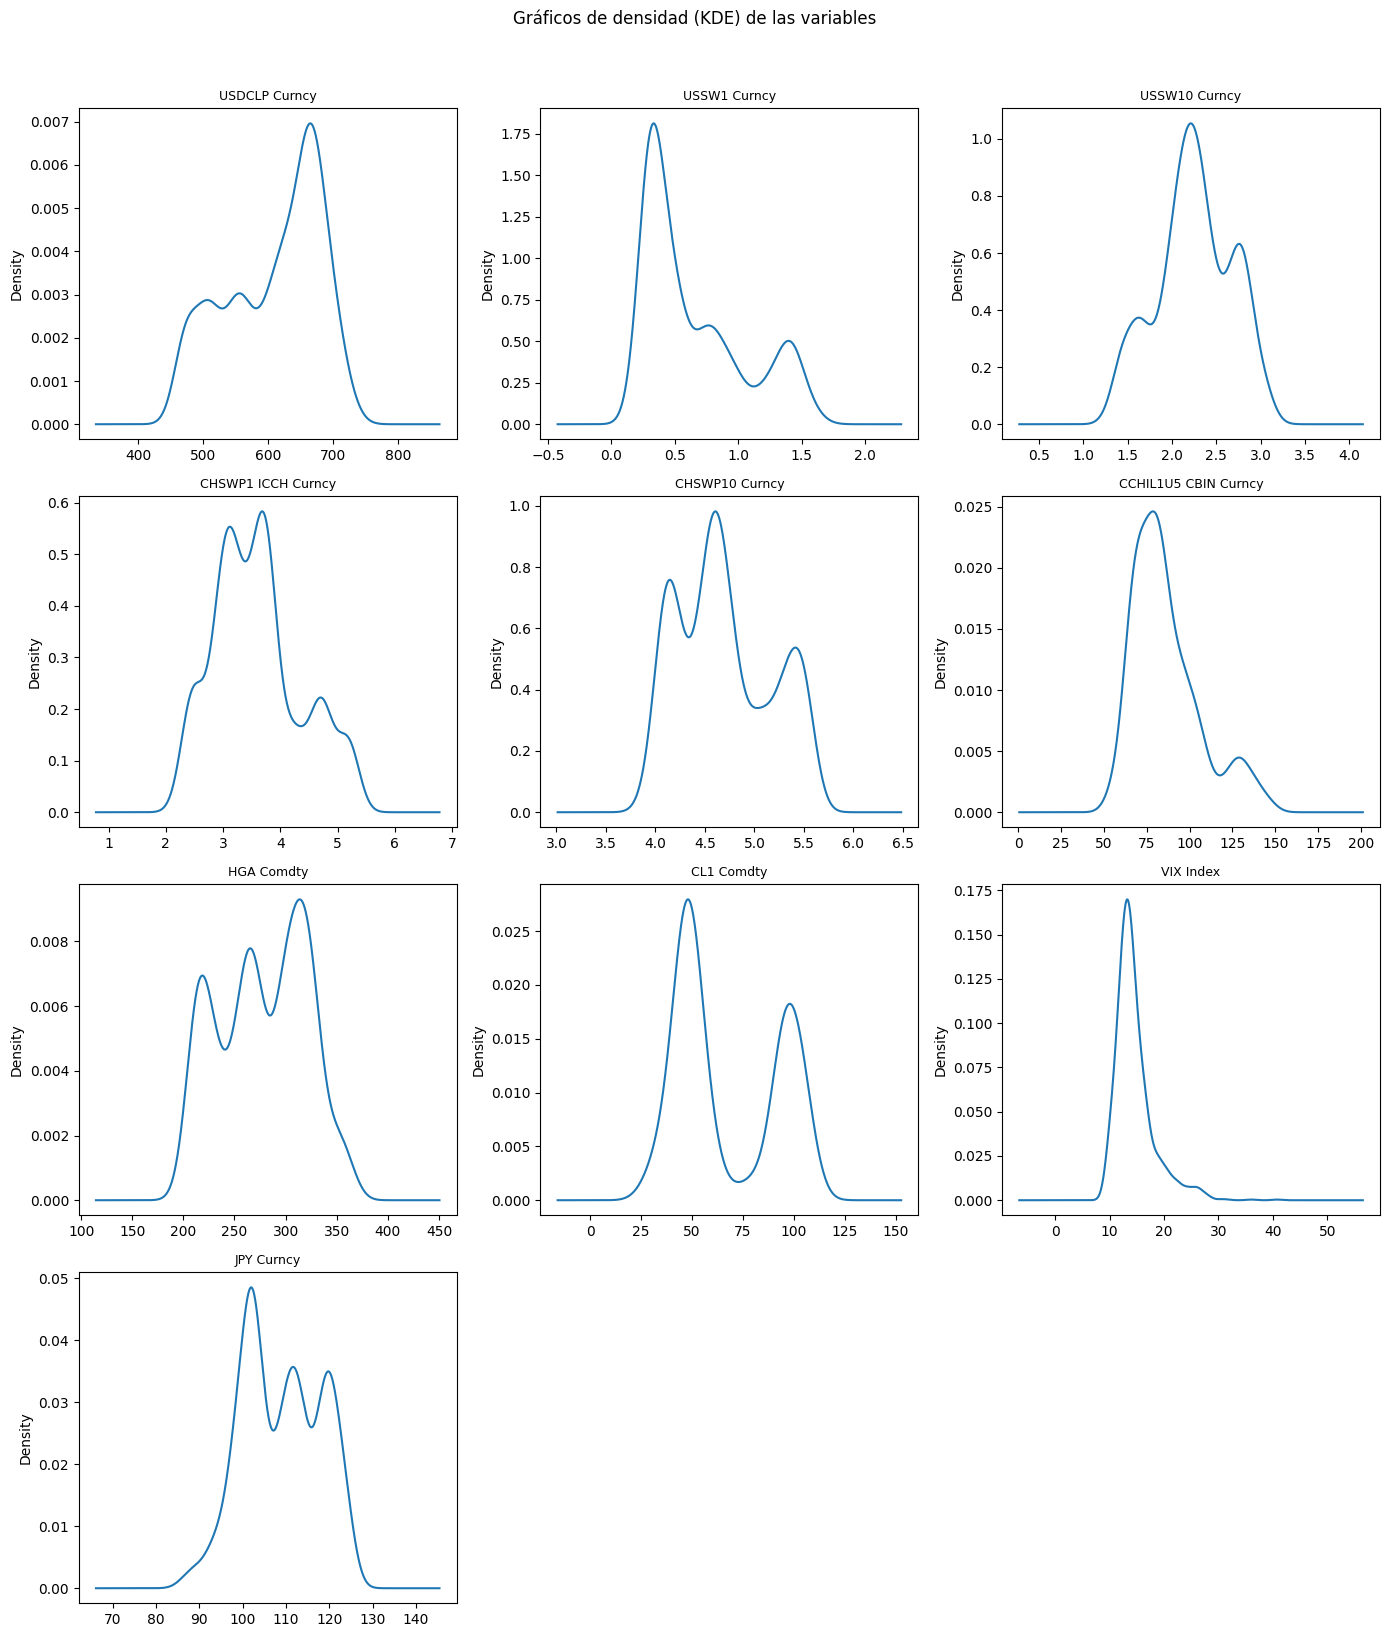

In [11]:
# 2. Gráficos de densidad (KDE) - una por variable
n_vars = len(numeric_cols)
n_rows = (n_vars + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()
for i, col in enumerate(numeric_cols):
    data[col].dropna().plot(kind='kde', ax=axes[i])
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Gráficos de densidad (KDE) de las variables', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

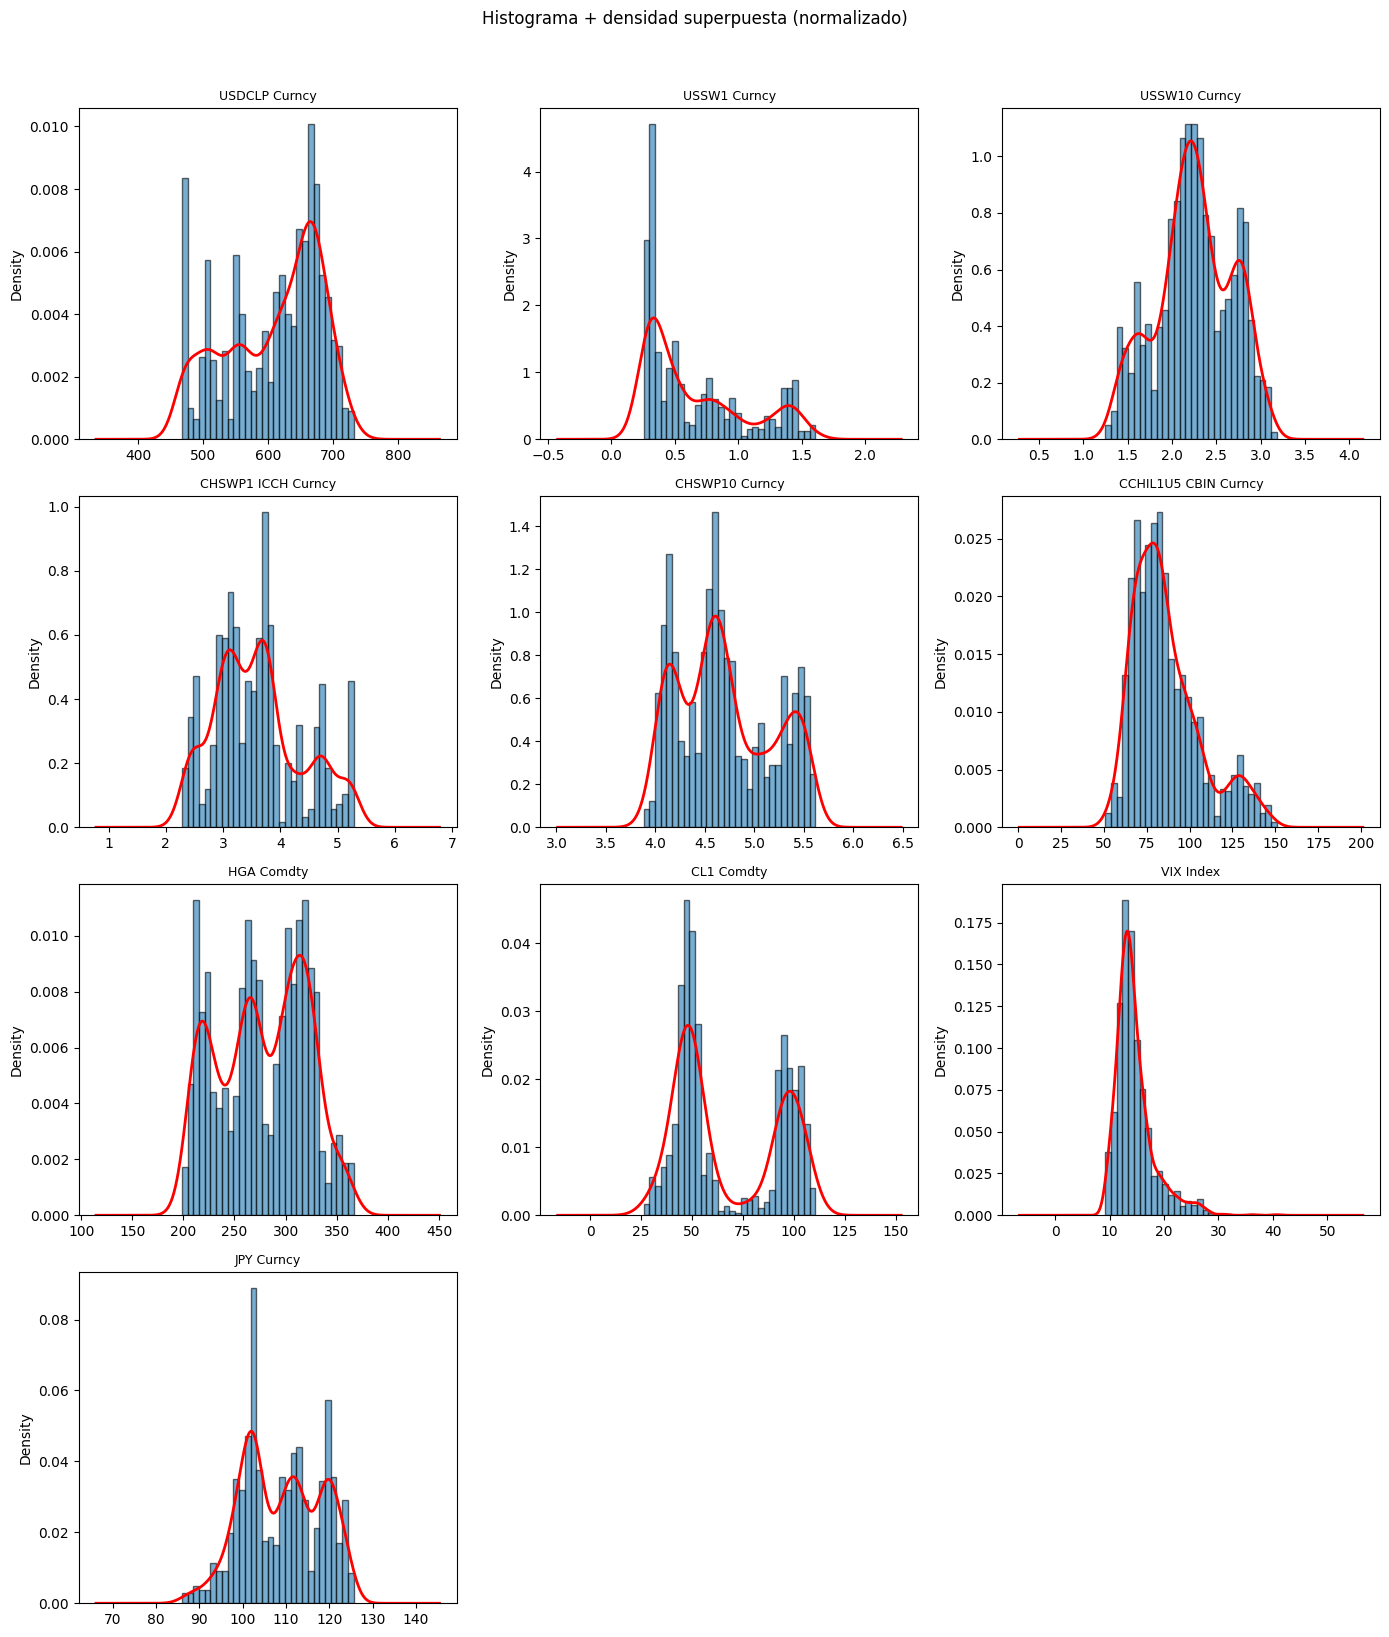

In [12]:
# 3. Histograma + densidad superpuesta (combinación)
n_vars = len(numeric_cols)
n_rows = (n_vars + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()
for i, col in enumerate(numeric_cols):
    data[col].dropna().hist(bins=30, density=True, alpha=0.6, edgecolor='black', ax=axes[i])
    data[col].dropna().plot(kind='kde', ax=axes[i], color='red', linewidth=2)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Histograma + densidad superpuesta (normalizado)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

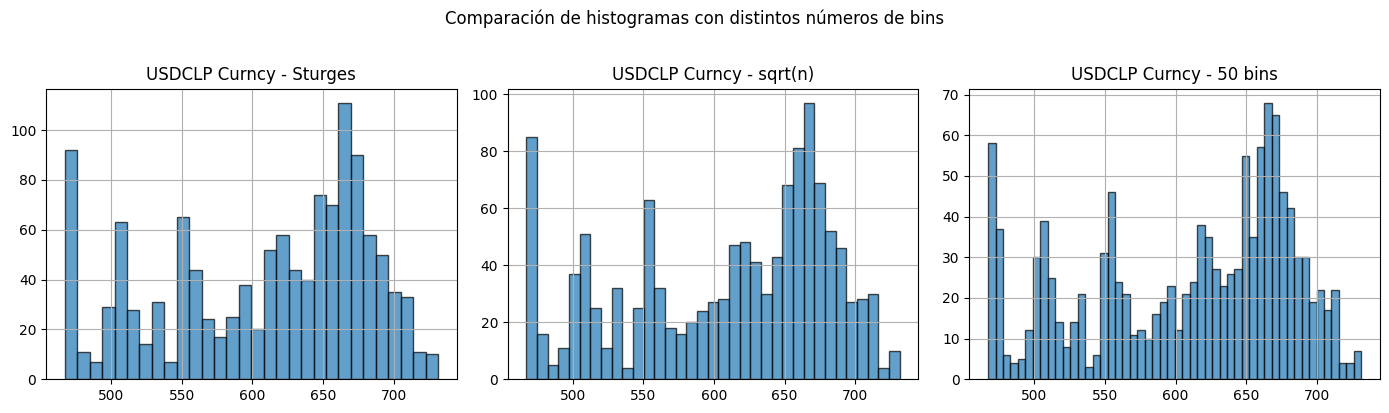

In [13]:
# 4. Histogramas con diferentes números de bins (Sturges, sqrt, Freeman-Diaconis)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
bins_methods = [('Sturges', 30), ('sqrt(n)', int(np.sqrt(len(data)))), ('50 bins', 50)]
for k, (label, n_bins) in enumerate(bins_methods):
    n_bins = int(n_bins) if isinstance(n_bins, float) else n_bins
    data[numeric_cols[0]].dropna().hist(bins=n_bins, ax=axes[k], edgecolor='black', alpha=0.7)
    axes[k].set_title(f'{numeric_cols[0]} - {label}')
plt.suptitle('Comparación de histogramas con distintos números de bins', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

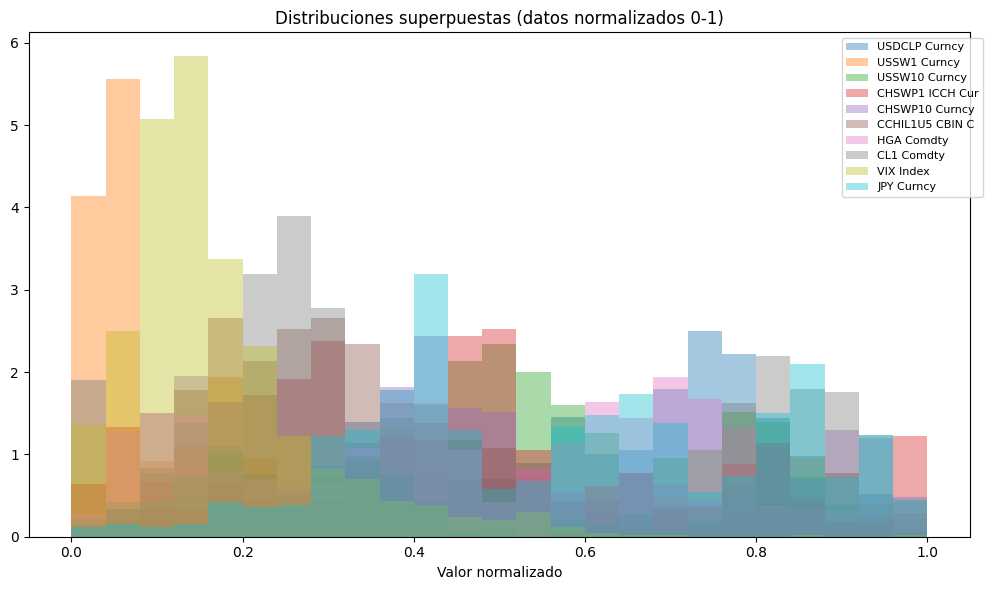

In [14]:
# 5. Histogramas horizontales (stacked) - todas las variables en escala comparable
data_norm = data[numeric_cols].dropna()
data_norm = (data_norm - data_norm.min()) / (data_norm.max() - data_norm.min() + 1e-8)
fig, ax = plt.subplots(figsize=(10, 6))
for col in numeric_cols:
    ax.hist(data_norm[col], bins=25, alpha=0.4, label=col[:15], density=True)
ax.legend(bbox_to_anchor=(1.02, 1), fontsize=8)
ax.set_title('Distribuciones superpuestas (datos normalizados 0-1)')
ax.set_xlabel('Valor normalizado')
plt.tight_layout()
plt.show()

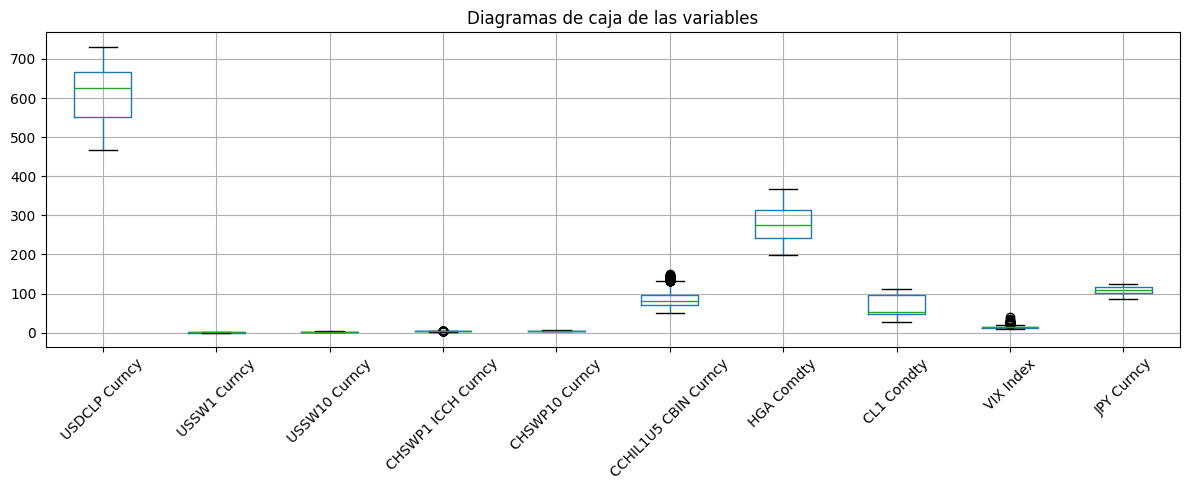

In [15]:
# 6. Box plots (diagramas de caja) - vista de dispersión y cuartiles
fig, ax = plt.subplots(figsize=(12, 5))
data[numeric_cols].boxplot(ax=ax, rot=45)
ax.set_title('Diagramas de caja de las variables')
plt.tight_layout()
plt.show()

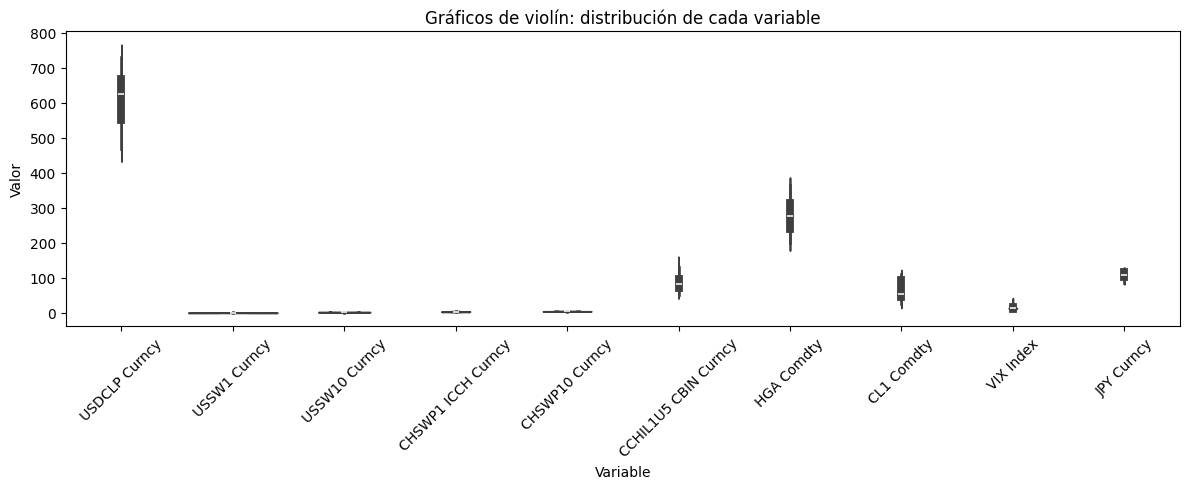

In [16]:
# 7. Gráficos de violín (violin plots) - densidad + box
fig, ax = plt.subplots(figsize=(12, 5))
data_melt = data[numeric_cols].melt(var_name='Variable', value_name='Valor')
sns.violinplot(data=data_melt, x='Variable', y='Valor', ax=ax)
ax.tick_params(axis='x', rotation=45)
ax.set_title('Gráficos de violín: distribución de cada variable')
plt.tight_layout()
plt.show()

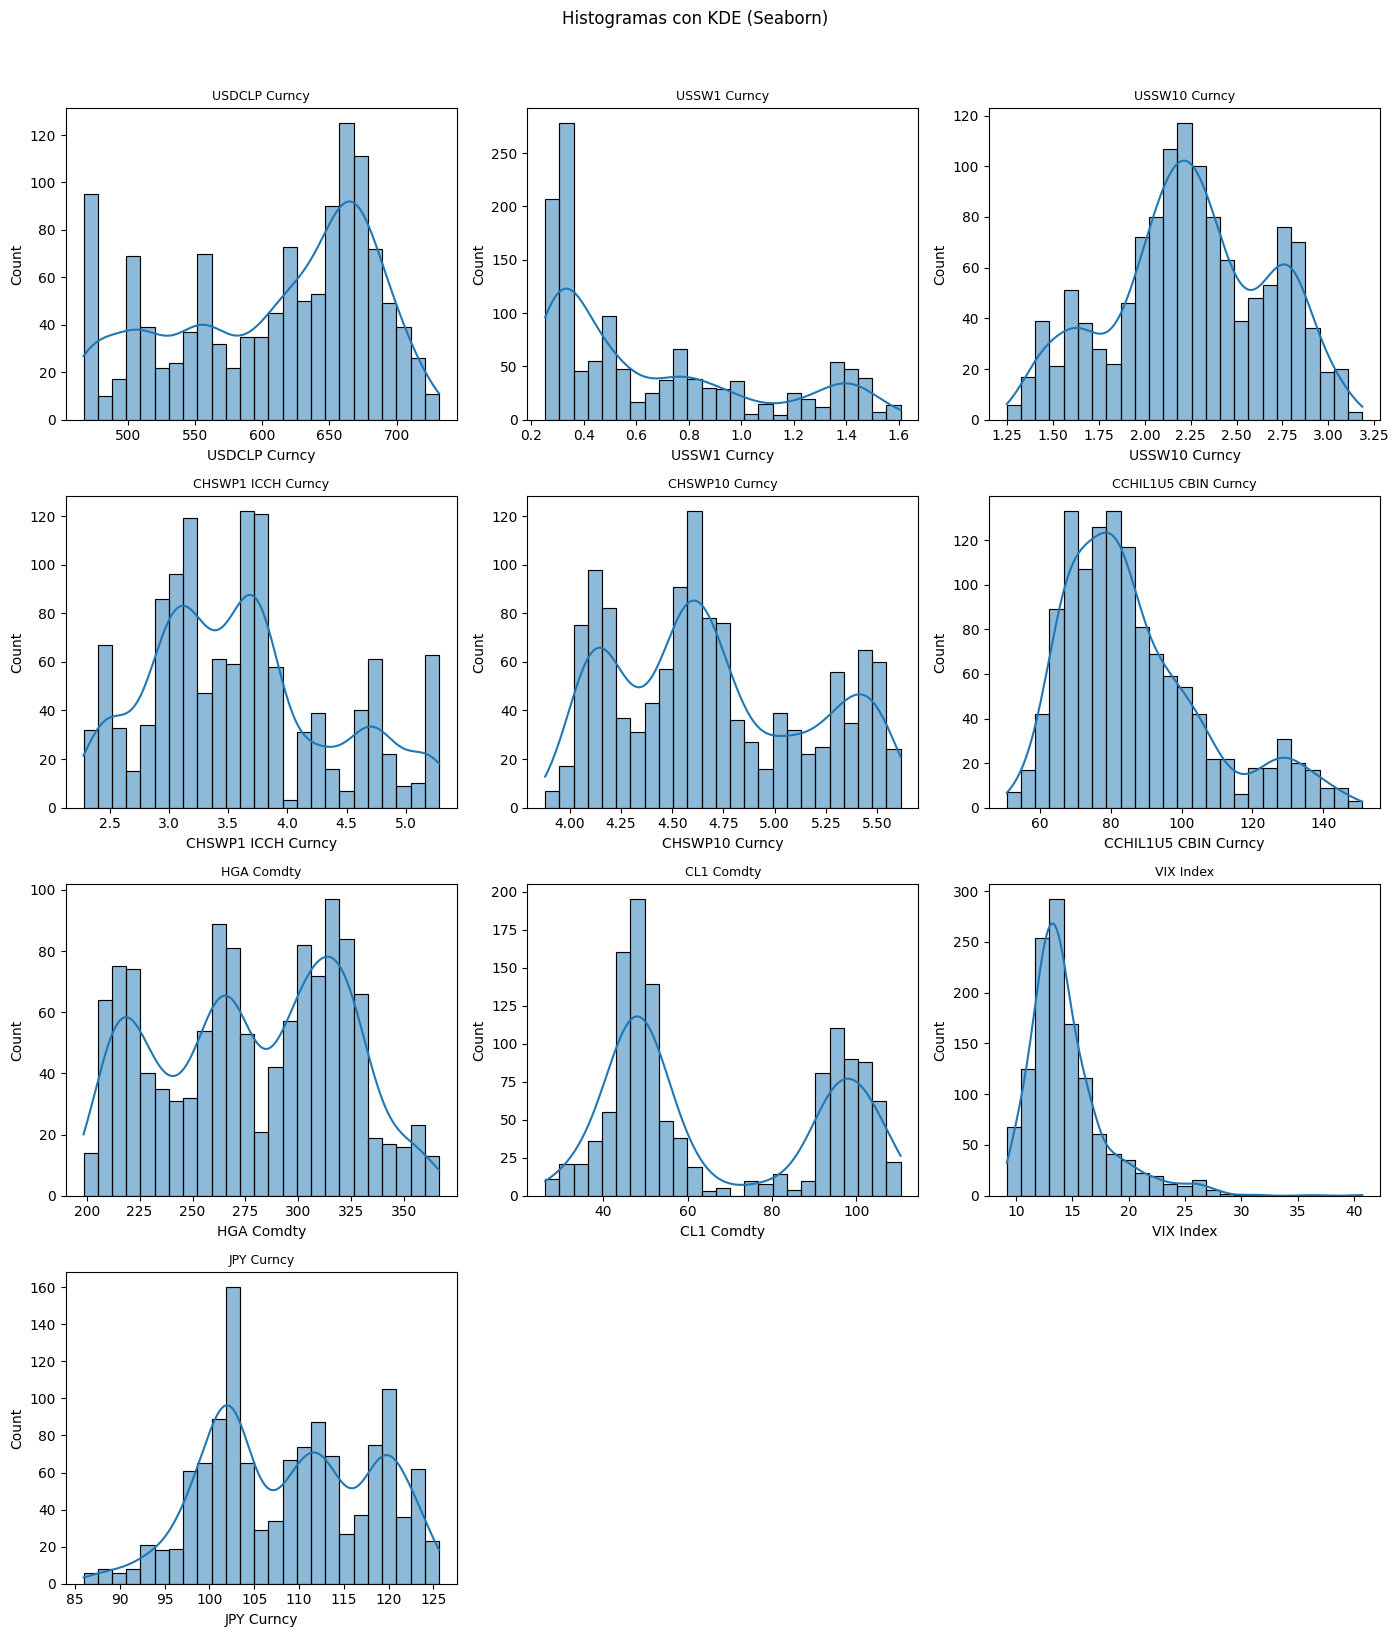

In [17]:
# 8. Seaborn histplot con KDE integrado
n_vars = len(numeric_cols)
n_rows = (n_vars + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(data[col].dropna(), kde=True, bins=25, ax=axes[i])
    axes[i].set_title(col, fontsize=9)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Histogramas con KDE (Seaborn)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

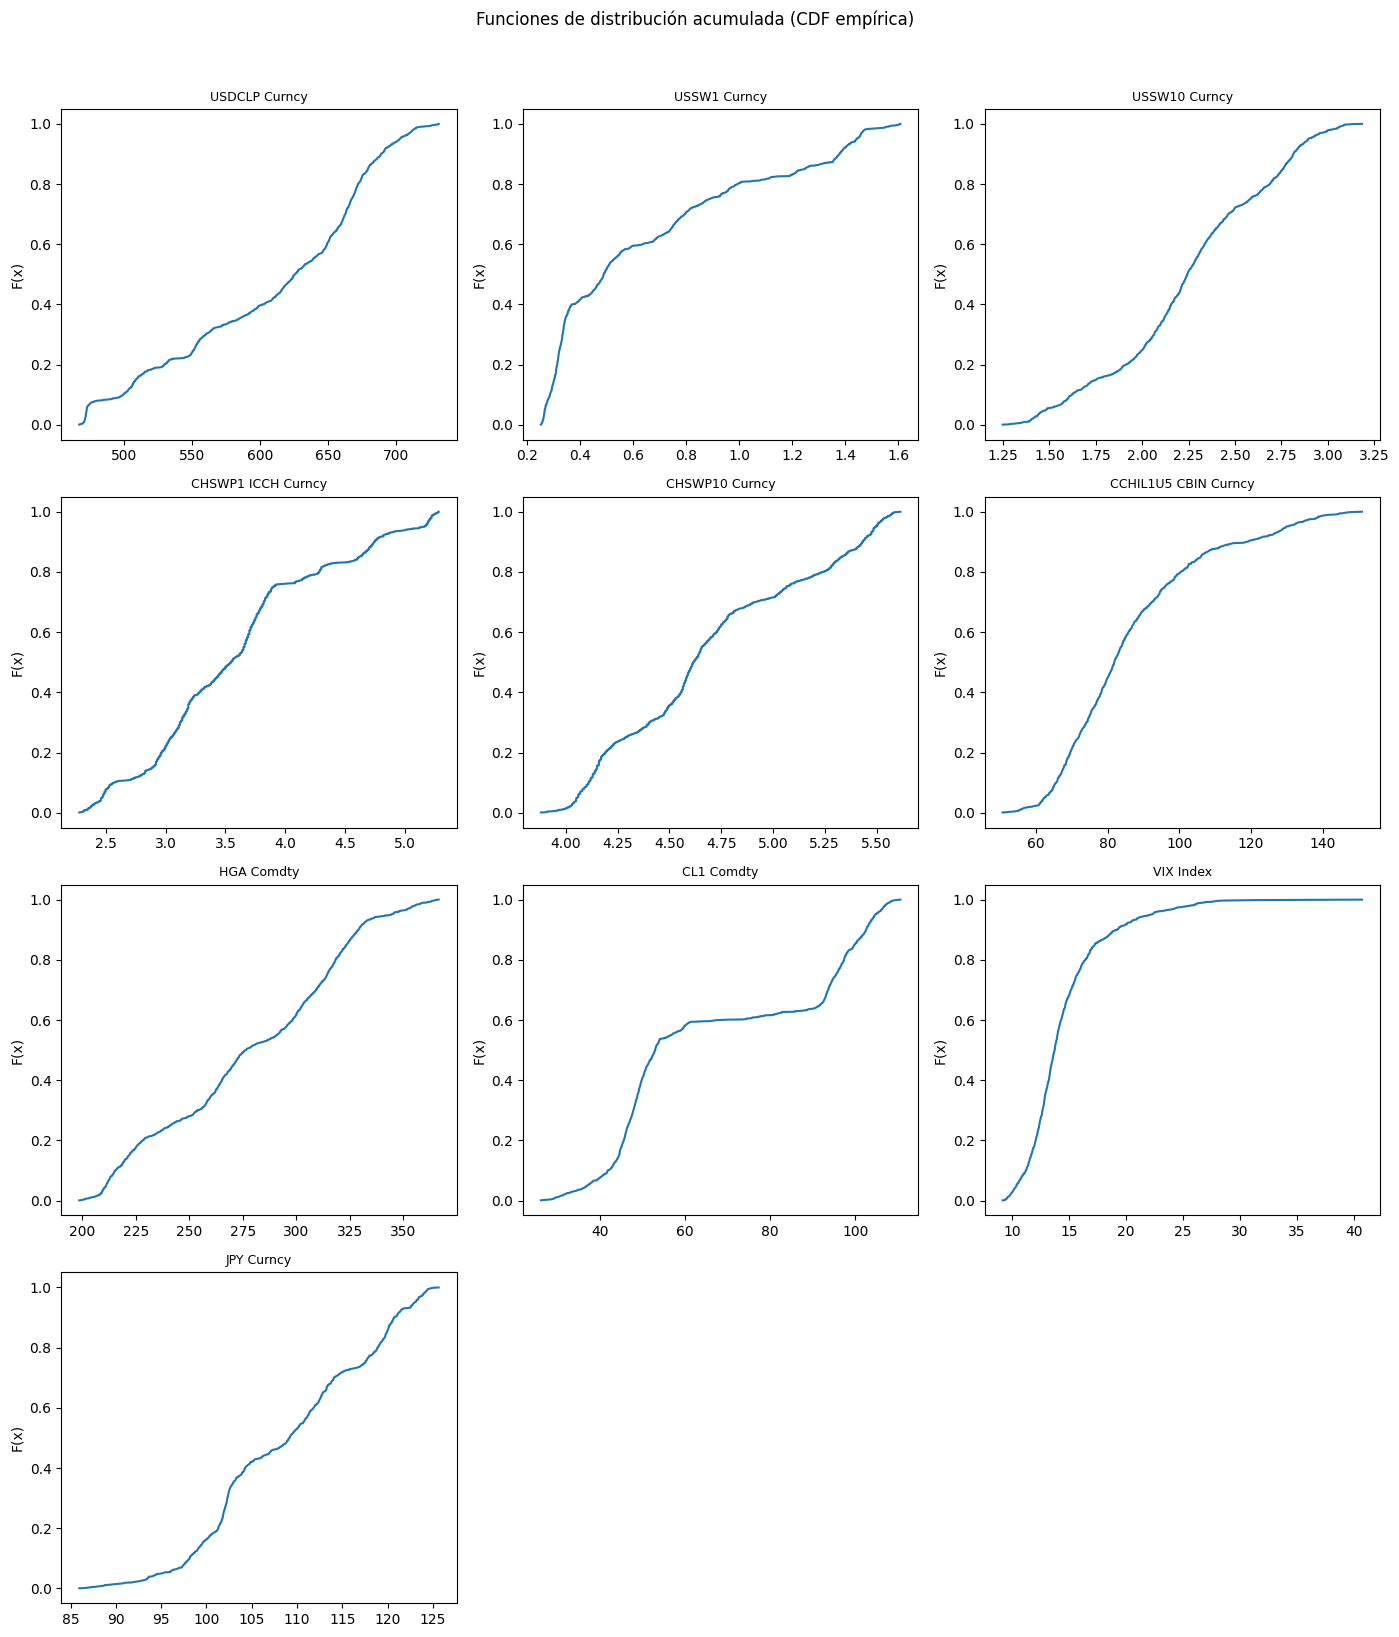

In [18]:
# 9. Histogramas acumulados (CDF) - función de distribución empírica
n_vars = len(numeric_cols)
n_rows = (n_vars + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
axes = np.atleast_1d(axes).flatten()
for i, col in enumerate(numeric_cols):
    sorted_vals = np.sort(data[col].dropna())
    cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    axes[i].plot(sorted_vals, cdf)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_ylabel('F(x)')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Funciones de distribución acumulada (CDF empírica)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

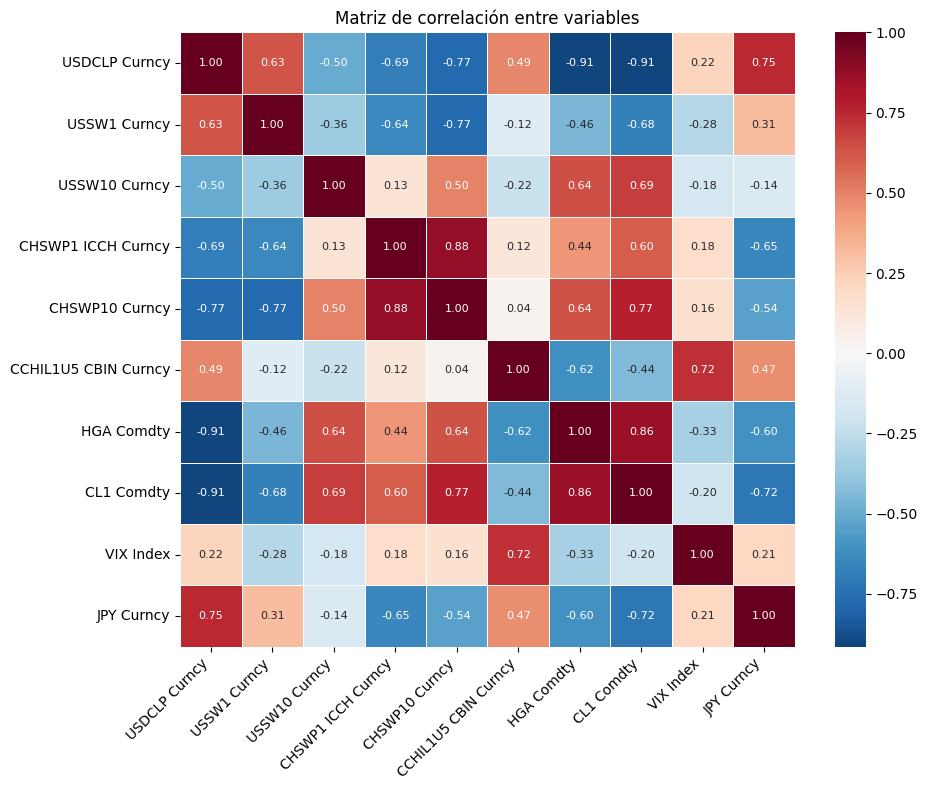

In [19]:
# Matriz de correlación (heatmap)
corr_matrix = data[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, 
            square=True, linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('Matriz de correlación entre variables')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Estimacion Modelos Regularizados

Desde la librería sklearn importaremos todos los modelos que utilizaremos en esta sesión, así como las métricas necesarias.

In [20]:
''' MODELOS a Estimar '''
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
'''METRICS'''
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error



## Separando Muestras (Training v/s Testing)


Como es usual, definiendo una fecha de corte. Separaremos la data en dos muestras. Una de entrenamiento (training) y otra para evaluar el desempeño de dichos modelos en una data diferente a la que fueron entrenados (testing)

In [21]:
# Separando variable explicada (y) de explicativas (x)
# Configurar la columna de fecha como índice para operaciones de series temporales
data_processed = data.set_index(data.columns[0])
data_processed.index = pd.to_datetime(data_processed.index)

# Definir y (objetivo) y x (predictores): USDCLP Curncy es la variable objetivo
y = data_processed.iloc[:, 0]
# Las características son las columnas restantes, excluyendo la última (1:-1)
x = data_processed.iloc[:, 1:-1]

# Umbral de corte para división entrenamiento/prueba
year_corte = '2016-06-19 00:00:00'
year_corte_dt = pd.to_datetime(year_corte)

# Entrenamiento (antes de la fecha de corte)
x_tr = x[x.index < year_corte_dt].copy(True)
y_tr = y[y.index < year_corte_dt].copy(True)
# Prueba (desde la fecha de corte, >= para incluir ese día)
x_tst = x[x.index >= year_corte_dt].copy(True)
y_tst = y[y.index >= year_corte_dt].copy(True)

## Modelo de Regresión Lineal: Análisis y Diagnósticos

Antes de comparar con Ridge, Lasso y Elastic Net, evaluamos un modelo de regresión lineal con las variables originales:
1. **Forward selection**: R2, AIC, BIC
2. **Significancia de los betas** (p-valores)
3. **Normalidad de residuos** (Shapiro-Wilk, Q-Q)
4. **Autocorrelación** (Durbin-Watson, Ljung-Box)
5. **Heterocedasticidad** (Breusch-Pagan, White)

In [22]:
try:
    import statsmodels.api as sm
    from statsmodels.stats.diagnostic import het_breuschpagan, het_white, acorr_ljungbox
    from statsmodels.stats.stattools import durbin_watson
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'statsmodels', '-q'])
    import statsmodels.api as sm
    from statsmodels.stats.diagnostic import het_breuschpagan, het_white, acorr_ljungbox
    from statsmodels.stats.stattools import durbin_watson
from scipy.stats import shapiro
import numpy as np

# Forward selection: R2, AIC, BIC
X_tr_const = sm.add_constant(x_tr)
remaining = list(x_tr.columns)
selected = []
results_fwd = []

while remaining:
    best_aic, best_var = np.inf, None
    for var in remaining:
        cols = ['const'] + selected + [var]
        model = sm.OLS(y_tr, X_tr_const[cols]).fit()
        if model.aic < best_aic:
            best_aic, best_bic, best_r2 = model.aic, model.bic, model.rsquared
            best_var = var
    if best_var is None:
        break
    selected.append(best_var)
    remaining.remove(best_var)
    results_fwd.append({'paso': len(selected), 'variable': best_var, 'R2': best_r2, 'AIC': best_aic, 'BIC': best_bic})

print("Forward Selection - R2, AIC, BIC por paso:")
display(pd.DataFrame(results_fwd))

Forward Selection - R2, AIC, BIC por paso:


,paso,variable,R2,AIC,BIC
0,1,HGA Comdty,0.917304,8187.936867,8197.554945
1,2,CHSWP1 ICCH Curncy,0.954095,7656.663607,7671.090725
2,3,CCHIL1U5 CBIN Curncy,0.959442,7546.465976,7565.702133
3,4,USSW1 Curncy,0.964378,7430.902637,7454.947833
4,5,CHSWP10 Curncy,0.966191,7385.560357,7414.414593
5,6,USSW10 Curncy,0.966549,7377.912102,7411.575377
6,7,VIX Index,0.966646,7377.282587,7415.754902
7,8,CL1 Comdty,0.966694,7377.993807,7421.275161


### Modelo OLS final (todas las variables seleccionadas por forward)

In [23]:
cols_final = ['const'] + selected
model_ols = sm.OLS(y_tr, X_tr_const[cols_final]).fit()
print("Resumen del modelo OLS - Significancia de betas (p-valores):")
print(model_ols.summary())

Resumen del modelo OLS - Significancia de betas (p-valores):
                            OLS Regression Results                            
Dep. Variable:          USDCLP Curncy   R-squared:                       0.967
Model:                            OLS   Adj. R-squared:                  0.966
Method:                 Least Squares   F-statistic:                     3254.
Date:                Thu, 19 Feb 2026   Prob (F-statistic):               0.00
Time:                        13:48:36   Log-Likelihood:                -3680.0
No. Observations:                 906   AIC:                             7378.
Df Residuals:                     897   BIC:                             7421.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------

### 1. Normalidad de residuos

Shapiro-Wilk: estadístico=0.9929, p-valor=0.0002
H0: residuos normales. p<0.05 → rechazar normalidad


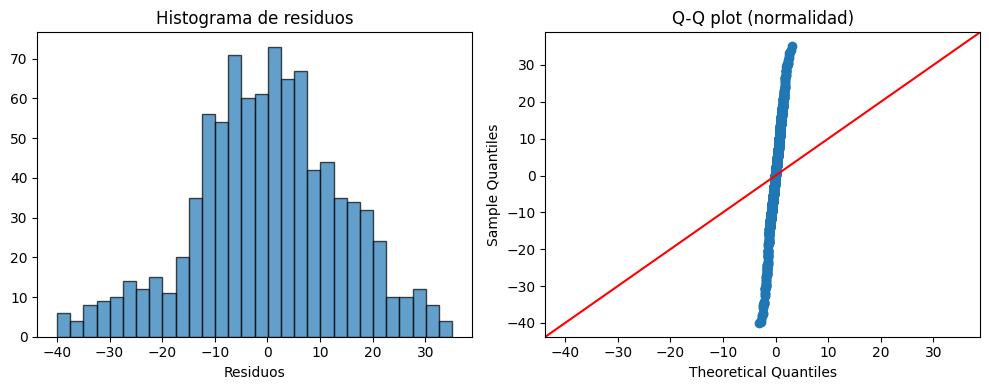

In [24]:
# 1. Normalidad de residuos (Shapiro-Wilk, Q-Q plot)
residuos = model_ols.resid
stat_shapiro, p_shapiro = shapiro(residuos)
print(f"Shapiro-Wilk: estadístico={stat_shapiro:.4f}, p-valor={p_shapiro:.4f}")
print("H0: residuos normales. p<0.05 → rechazar normalidad")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(residuos, bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title('Histograma de residuos')
axes[0].set_xlabel('Residuos')
sm.qqplot(residuos, line='45', ax=axes[1])
axes[1].set_title('Q-Q plot (normalidad)')
plt.tight_layout()
plt.show()

### 2. Autocorrelación (Durbin-Watson, Ljung-Box)

In [25]:
dw = durbin_watson(residuos)
print(f"Durbin-Watson: {dw:.4f} (≈2: no autocorr; <1.5 o >2.5: posible autocorr)")

lb_test = acorr_ljungbox(residuos, lags=10, return_df=True)
print("\nLjung-Box (H0: no autocorr hasta lag k):")
print(lb_test)

Durbin-Watson: 0.0686 (≈2: no autocorr; <1.5 o >2.5: posible autocorr)

Ljung-Box (H0: no autocorr hasta lag k):
        lb_stat      lb_pvalue
1    846.641237  3.906342e-186
2   1649.575763   0.000000e+00
3   2413.273036   0.000000e+00
4   3138.391292   0.000000e+00
5   3831.268972   0.000000e+00
6   4497.291170   0.000000e+00
7   5138.331411   0.000000e+00
8   5753.769029   0.000000e+00
9   6343.822917   0.000000e+00
10  6906.096161   0.000000e+00


### 3. Heterocedasticidad (Breusch-Pagan, White)

In [26]:
exog = X_tr_const[cols_final]
bp_lm, bp_pval, bp_fstat, bp_fpval = het_breuschpagan(residuos, exog)
print(f"Breusch-Pagan: LM={bp_lm:.4f}, p-valor={bp_pval:.4f}")
print("H0: homocedasticidad. p<0.05 → heterocedasticidad")

white_lm, white_pval, white_fstat, white_fpval = het_white(residuos, exog)
print(f"\nWhite: LM={white_lm:.4f}, p-valor={white_pval:.4f}")

Breusch-Pagan: LM=193.3483, p-valor=0.0000
H0: homocedasticidad. p<0.05 → heterocedasticidad

White: LM=556.2706, p-valor=0.0000


# Funcion Generadora de Rezagos

Esta función nos permitirá generar rezagos de las variables disponibles en la base de datos.


In [27]:
def crealags(base,lag_ini,nrolags):
    for lags in range(lag_ini,  nrolags+lag_ini): #Parte del rezago que definamos, no desde 1
        slag=base.shift(lags).copy(True)
        slag.columns=[str(col) + '_lag'+str(lags) for col in base.columns]
        if lags==lag_ini:#Bloque de datos inicial
            rezagos=pd.concat([slag], axis=1).copy(True)#genera primer bloque de datos
        else: rezagos=pd.concat([rezagos,slag], axis=1).copy(True) #genera el resto del bloque de datos
    return rezagos

## Generando Rezagos en la Data

Haciendo uso de la función recién generada, generaremos rezagos para cada una de las variables del dataframe que hemos importado desde excel. Para cada variable (incluye la dependiente), se han generado 5 rezagos.

In [28]:
nrolags=5
lag_ini = 1
rezagos = crealags(data,lag_ini,nrolags)
rezagos.head(10)

,Unnamed: 0_lag1,USDCLP Curncy_lag1,USSW1 Curncy_lag1,USSW10 Curncy_lag1,CHSWP1 ICCH Curncy_lag1,CHSWP10 Curncy_lag1,CCHIL1U5 CBIN Curncy_lag1,HGA Comdty_lag1,CL1 Comdty_lag1,VIX Index_lag1,...,USDCLP Curncy_lag5,USSW1 Curncy_lag5,USSW10 Curncy_lag5,CHSWP1 ICCH Curncy_lag5,CHSWP10 Curncy_lag5,CCHIL1U5 CBIN Curncy_lag5,HGA Comdty_lag5,CL1 Comdty_lag5,VIX Index_lag5,JPY Curncy_lag5
0,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2012-12-28,479.470,0.3340,1.7630,5.23,5.47000,72.603,344.35,90.80,22.72,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2012-12-31,476.404,0.3240,1.8395,5.26,5.47000,72.479,350.65,91.82,18.02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2013-01-01,475.382,0.3210,1.8395,5.27,5.47000,72.136,354.90,92.47,16.35,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2013-01-02,474.360,0.3205,1.8781,5.28,5.50000,70.128,359.15,93.12,14.68,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2013-01-03,472.420,0.3215,1.9455,5.28,5.53000,67.005,357.35,92.92,14.56,...,479.470,0.3340,1.7630,5.23,5.47,72.603,344.35,90.80,22.72,85.96
6,2013-01-04,473.120,0.3300,1.9360,5.27,5.55000,66.833,355.30,93.09,13.83,...,476.404,0.3240,1.8395,5.26,5.47,72.479,350.65,91.82,18.02,86.75
7,2013-01-07,471.340,0.3280,1.9270,5.28,5.58000,68.502,354.05,93.19,13.79,...,475.382,0.3210,1.8395,5.27,5.47,72.136,354.90,92.47,16.35,86.70
8,2013-01-08,472.250,0.3230,1.8910,5.27,5.55499,69.658,353.75,93.15,13.62,...,474.360,0.3205,1.8781,5.28,5.50,70.128,359.15,93.12,14.68,87.34
9,2013-01-09,470.950,0.3140,1.8875,5.25,5.54000,68.333,353.90,93.10,13.81,...,472.420,0.3215,1.9455,5.28,5.53,67.005,357.35,92.92,14.56,87.24


## Muestras training y testing con rezagos

In [29]:
# First, ensure rezagos has a datetime index and drop redundant lagged date columns
# rezagos comes from crealags(data, lag_ini, nrolags), which used the raw `data` (integer index).
# So, `rezagos` itself has an integer index.
# We need to make it datetime indexed for proper alignment and slicing.
rezagos_indexed = rezagos.copy()
# Find the column that contains the original date (e.g., 'Unnamed: 0_lag1') to set as index
date_lag_col = [col for col in rezagos_indexed.columns if 'Unnamed: 0_lag' in col][0]
rezagos_indexed = rezagos_indexed.set_index(date_lag_col)
rezagos_indexed.index = pd.to_datetime(rezagos_indexed.index)
# Drop all 'Unnamed: 0_lagX' columns from the data, as the index now handles the date
rezagos_indexed = rezagos_indexed.drop(columns=[col for col in rezagos_indexed.columns if 'Unnamed: 0_lag' in col])

# y_original is the non-lagged target variable, which is `USDCLP Curncy` from `data_processed`
# (data_processed already has a datetime index)
y_original = data_processed['USDCLP Curncy']

# Concatenate the original target with the lagged features.
# This creates a DataFrame where the first column is the original target,
# and subsequent columns are all the lagged features, correctly aligned by date.
data_rezagos = pd.concat([y_original, rezagos_indexed], axis=1).dropna()

# Now define y (target) and x (features) from data_rezagos
y = data_rezagos.iloc[:, 0]
x = data_rezagos.iloc[:, 1:] # All other columns are lagged features

# Umbral de Corte
year_corte = '2016-06-19 00:00:00'
# Convert year_corte to a datetime object for proper comparison with the DatetimeIndex
year_corte_dt = pd.to_datetime(year_corte)

# Trainig
x_tr = x[x.index < year_corte_dt].copy(True)
y_tr = y[y.index < year_corte_dt].copy(True)
# Testing
x_tst = x[x.index >= year_corte_dt].copy(True) # Using >= to include the cutoff date in the testing set
y_tst = y[y.index >= year_corte_dt].copy(True)

## Concatenando Rezagos con Data Original

Lo que ahora haremos será concatenar ambos DataFrame, eliminando en el proceso, todos los datos que perdimos al realizar los rezagos de las variables (**.dropna()**)

In [30]:
data_rezagos=pd.concat([data.iloc[:,0],rezagos],axis=1).dropna()

In [31]:
data_rezagos

,Unnamed: 0,Unnamed: 0_lag1,USDCLP Curncy_lag1,USSW1 Curncy_lag1,USSW10 Curncy_lag1,CHSWP1 ICCH Curncy_lag1,CHSWP10 Curncy_lag1,CCHIL1U5 CBIN Curncy_lag1,HGA Comdty_lag1,CL1 Comdty_lag1,...,USDCLP Curncy_lag5,USSW1 Curncy_lag5,USSW10 Curncy_lag5,CHSWP1 ICCH Curncy_lag5,CHSWP10 Curncy_lag5,CCHIL1U5 CBIN Curncy_lag5,HGA Comdty_lag5,CL1 Comdty_lag5,VIX Index_lag5,JPY Curncy_lag5
5,2013-01-04,2013-01-03,472.4200,0.3215,1.9455,5.2800,5.530000,67.005,357.35,92.92,...,479.470,0.3340,1.7630,5.23,5.470,72.603,344.35,90.80,22.72,85.96
6,2013-01-07,2013-01-04,473.1200,0.3300,1.9360,5.2700,5.550000,66.833,355.30,93.09,...,476.404,0.3240,1.8395,5.26,5.470,72.479,350.65,91.82,18.02,86.75
7,2013-01-08,2013-01-07,471.3400,0.3280,1.9270,5.2800,5.580000,68.502,354.05,93.19,...,475.382,0.3210,1.8395,5.27,5.470,72.136,354.90,92.47,16.35,86.70
8,2013-01-09,2013-01-08,472.2500,0.3230,1.8910,5.2700,5.554990,69.658,353.75,93.15,...,474.360,0.3205,1.8781,5.28,5.500,70.128,359.15,93.12,14.68,87.34
9,2013-01-10,2013-01-09,470.9500,0.3140,1.8875,5.2500,5.540000,68.333,353.90,93.10,...,472.420,0.3215,1.9455,5.28,5.530,67.005,357.35,92.92,14.56,87.24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1246,2017-10-09,2017-10-06,632.4500,1.5998,2.3145,2.5300,4.230000,55.778,302.90,49.29,...,638.750,1.5674,2.3005,2.56,4.210,57.595,295.55,50.58,9.45,112.77
1247,2017-10-10,2017-10-09,630.0125,1.6043,2.3173,2.5075,4.237538,56.221,303.10,49.58,...,633.300,1.5731,2.2812,2.58,4.200,55.670,296.35,50.42,9.51,112.85
1248,2017-10-11,2017-10-10,629.2000,1.6044,2.3163,2.5000,4.240050,56.629,306.05,50.92,...,631.670,1.5810,2.2825,2.59,4.239,55.235,295.90,49.98,9.63,112.76
1249,2017-10-12,2017-10-11,627.0400,1.6075,2.3034,2.4600,4.220150,55.995,309.55,51.30,...,628.630,1.5928,2.3027,2.58,4.230,55.411,304.65,50.79,9.19,112.82


## Declaracion de Modelos a Estimar (forma conveniente)

En esta función, declararemos todos los modelos a utilizar, dentro de listas que ocuparemos más adelante.

In [32]:
def creamodelos():
    print('Creando Modelos...')
    names = [
        "LinearRegression",
        'Ridge',
        'Lasso',
        'ElasticNet'
    ]

    regresores = [
        LinearRegression(),
        Ridge(),
        Lasso(),
        ElasticNet(),
    ]

    print('Lista de modelos creados...')
    print(names)
    print('\n')
    return names, regresores

names, regresores = creamodelos()

Creando Modelos...
Lista de modelos creados...
['LinearRegression', 'Ridge', 'Lasso', 'ElasticNet']




# Estimación + Métricas Training

Para ajustar los modelos que hemos declarado anteriormente (**creamodelos**), haremos uso de un loop que irá tomando cada uno de estos modelos declarados, estimándolo y simultáneamente calculando sus métricas de desempeño en un DataFrame que consolida toda la información.

In [33]:
modelos=[]
metricas_training=[]
counter=1
for name, modelo in zip(names, regresores):
    #print("entrenando modelo")
    #print(name)

    modelo.fit(x_tr,y_tr)

    #guarda el objeto modelo entrenado y colocale un id counter
    modelos.append({'algo':modelo,'idmod':counter})
    pred_training=modelo.predict(x_tr)

    def metricas(y_real,pred,counter,name):
        res=[]
        #%%Creacion y exportacion de métricas del modelo.
        MAE=mean_absolute_error(y_real,pred)
        RMSE=(mean_squared_error(y_real,pred))**0.5

        res.append((counter,name,MAE,RMSE))
        return res

    res_tr=metricas(y_tr,pred_training,counter,name)
    metricas_training.append(res_tr)
    counter=counter+1


from itertools import chain
def flatten(listOfLists):
    "Flatten one level of nesting"
    return chain.from_iterable(listOfLists)

metricas_training=list(flatten(metricas_training))
resultados_training=pd.DataFrame(data=metricas_training, columns=['id_modelo','Modelo','MAE','RMSE'])
resultados_training

,id_modelo,Modelo,MAE,RMSE
0,1,LinearRegression,1.811175e-13,2.233521e-13
1,2,Ridge,3.001916e-04,3.859971e-04
2,3,Lasso,1.125324e-02,1.301968e-02
3,4,ElasticNet,5.696203e-03,6.595870e-03


# Estimacion + Métricas Testing

Repetimos el mismo proceso para la muestra de testing.

In [34]:
# IMPORTANTE: Usamos los modelos YA ENTRENADOS en training (celda anterior).
# NO re-entrenamos en testing; eso sería un error metodológico (data leakage).
metricas_testing=[]
counter=1
for name, mod_dict in zip(names, modelos):
    modelo = mod_dict['algo']  # modelo ya entrenado en x_tr, y_tr
    pred_testing=modelo.predict(x_tst)

    def metricas(y_real,pred,counter,name):
        res=[]
        #%%Creacion y exportacion de métricas del modelo.
        MAE=mean_absolute_error(y_real,pred)
        RMSE=(mean_squared_error(y_real,pred))**0.5

        res.append((counter,name,MAE,RMSE))
        return res

    res_tst=metricas(y_tst,pred_testing,counter,name)
    metricas_testing.append(res_tst)
    counter=counter+1



metricas_testing=list(flatten(metricas_testing))
resultados_testing=pd.DataFrame(data=metricas_testing, columns=['id_modelo','Modelo','MAE','RMSE'])
resultados_testing


,id_modelo,Modelo,MAE,RMSE
0,1,LinearRegression,1.867240e-13,2.395248e-13
1,2,Ridge,3.508108e-04,4.425317e-04
2,3,Lasso,1.147597e-02,1.172083e-02
3,4,ElasticNet,6.195469e-03,6.381157e-03
